# Análisis de Datos II — Actividad 2

## 1. Librerías

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor, IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

RANDOM_STATE = 42

## 2. Carga y preparación del dataset

El código busca el CSV primero en la misma carpeta de la notebook y luego en `/mnt/data/`,
de modo que pueda ejecutarse tanto localmente como en un entorno tipo Colab.

In [ ]:
data_path = ["/mnt/data/ds_salaries.csv"]

if data_path is None:
    raise FileNotFoundError("No se encontró ds_salaries.csv.")
df = pd.read_csv(data_path)
print(f"Dataset cargado desde: {data_path}")
print("Shape:", df.shape)
display(df.head())

Dataset cargado desde: ds_salaries.csv
Shape: (3755, 11)


,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2023,SE,FT,Principal Data Scientist,80000,EUR,85847,ES,100,ES,L
1,2023,MI,CT,ML Engineer,30000,USD,30000,US,100,US,S
2,2023,MI,CT,ML Engineer,25500,USD,25500,US,100,US,S
3,2023,SE,FT,Data Scientist,175000,USD,175000,CA,100,CA,M
4,2023,SE,FT,Data Scientist,120000,USD,120000,CA,100,CA,M


### División 

In [4]:
reference = df[df["work_year"].isin([2020, 2021])].copy()
actual = df[df["work_year"].isin([2022, 2023])].copy()

print(f"Referencia 2020-2021: {len(reference)} registros")
print(f"Actual 2022-2023    : {len(actual)} registros")

assert len(reference) + len(actual) == len(df)

Referencia 2020-2021: 306 registros
Actual 2022-2023    : 3449 registros


## 3. Variables seleccionadas

Se utilizan cuatro variables relevantes de la Actividad 1:

- `salary_in_usd`: variable objetivo del modelo de la Actividad 1.
- `experience_level`: nivel de experiencia profesional.
- `remote_ratio`: porcentaje de trabajo remoto.
- `company_size`: tamaño de la empresa.

In [5]:
selected_features = [
    "salary_in_usd",
    "experience_level",
    "remote_ratio",
    "company_size",
]

display(df[selected_features].head())

,salary_in_usd,experience_level,remote_ratio,company_size
0,85847,SE,100,L
1,30000,MI,100,S
2,25500,MI,100,S
3,175000,SE,100,M
4,120000,SE,100,M


# 4. Calidad de datos


1. **Completitud** ausencia de valores nulos.
2. **Validez** valores dentro del dominio esperado.
3. **Esquema** tipos de datos compatibles con el significado de cada variable.
4. **Unicidad** existencia de filas completas duplicadas.

In [ ]:
VALID_DOMAINS = {
    "experience_level": {"EN", "MI", "SE", "EX"},
    "remote_ratio": {0, 50, 100},
    "company_size": {"S", "M", "L"},
}

def quality_checks(data, period_name):
    rows = []

    for col in selected_features:
        # 1) Completitud
        n_missing = int(data[col].isna().sum())
        rows.append({
            "periodo": period_name,
            "variable": col,
            "chequeo": "Completitud",
            "resultado": "OK" if n_missing == 0 else "ALERTA",
            "detalle": f"{n_missing} nulos ({100*n_missing/len(data):.2f}%)"
        })

        # 2) Validez
        if col == "salary_in_usd":
            invalid = int((data[col] <= 0).sum())
            detail = f"{invalid} valores <= 0"
        else:
            invalid = int((~data[col].isin(VALID_DOMAINS[col])).sum())
            detail = f"{invalid} valores fuera del dominio"

        rows.append({
            "periodo": period_name,
            "variable": col,
            "chequeo": "Validez",
            "resultado": "OK" if invalid == 0 else "ALERTA",
            "detalle": detail
        })

        # 3) Esquema
        if col in ["salary_in_usd", "remote_ratio"]:
            type_ok = pd.api.types.is_numeric_dtype(data[col])
            expected = "numérico"
        else:
            type_ok = (
                pd.api.types.is_object_dtype(data[col])
                or isinstance(data[col].dtype, pd.CategoricalDtype)
            )
            expected = "categórico"

        rows.append({
            "periodo": period_name,
            "variable": col,
            "chequeo": "Esquema/tipo",
            "resultado": "OK" if type_ok else "ALERTA",
            "detalle": f"dtype={data[col].dtype}; esperado={expected}"
        })

    return pd.DataFrame(rows)

quality_table = pd.concat([quality_checks(reference, "Referencia 2020-2021"),quality_checks(actual, "Actual 2022-2023")],
 ignore_index=True)

display(quality_table)

,periodo,variable,chequeo,resultado,detalle
0,Referencia 2020-2021,salary_in_usd,Completitud,OK,0 nulos (0.00%)
1,Referencia 2020-2021,salary_in_usd,Validez,OK,0 valores <= 0
2,Referencia 2020-2021,salary_in_usd,Esquema/tipo,OK,dtype=int64; esperado=numérico
3,Referencia 2020-2021,experience_level,Completitud,OK,0 nulos (0.00%)
4,Referencia 2020-2021,experience_level,Validez,OK,0 valores fuera del dominio
5,Referencia 2020-2021,experience_level,Esquema/tipo,OK,dtype=object; esperado=categórico
6,Referencia 2020-2021,remote_ratio,Completitud,OK,0 nulos (0.00%)
7,Referencia 2020-2021,remote_ratio,Validez,OK,0 valores fuera del dominio
8,Referencia 2020-2021,remote_ratio,Esquema/tipo,OK,dtype=int64; esperado=numérico
9,Referencia 2020-2021,company_size,Completitud,OK,0 nulos (0.00%)


### Chequeo de unicidad

In [7]:
duplicate_summary = pd.DataFrame([
    {
        "periodo": "Referencia 2020-2021",
        "n_registros": len(reference),
        "duplicados_exactos": int(reference.duplicated().sum()),
        "pct_duplicados": 100 * reference.duplicated().mean()
    },
    {
        "periodo": "Actual 2022-2023",
        "n_registros": len(actual),
        "duplicados_exactos": int(actual.duplicated().sum()),
        "pct_duplicados": 100 * actual.duplicated().mean()
    }
])

display(
    duplicate_summary.style.format({"pct_duplicados": "{:.2f}%"})
)

,periodo,n_registros,duplicados_exactos,pct_duplicados
0,Referencia 2020-2021,306,3,0.98%
1,Actual 2022-2023,3449,1168,33.86%


### Interpretación de calidad

Los cuatro campos seleccionados no presentan nulos, valores inválidos ni tipos incompatibles.
El principal problema de calidad es la duplicación de filas completas:

- Referencia 2020–2021: **3 duplicados de 306 registros (0.98%)**.
- Actual 2022–2023: **1,168 duplicados de 3,449 registros (33.86%)**.

Por ese motivo, los duplicados se eliminan y después de esta limpieza quedan **303 registros de referencia** y **2,281 registros actuales**.

In [ ]:
reference_clean = reference.drop_duplicates().copy()
actual_clean = actual.drop_duplicates().copy()

df_clean = (pd.concat([reference_clean, actual_clean], axis=0).sort_index().copy())

print(f"Referencia sin duplicados: {len(reference_clean)}")
print(f"Actual sin duplicados    : {len(actual_clean)}")
print(f"Total sin duplicados     : {len(df_clean)}")

Referencia sin duplicados: 303
Actual sin duplicados    : 2281
Total sin duplicados     : 2584


# 5. Drift con Population Stability Index (PSI)


- `PSI < 0.10`: no se considera evidencia suficiente de drift.
- `PSI >= 0.10`: se considera drift.

In [9]:
def psi_numeric(reference_series, actual_series, bins=10, eps=1e-6):
    ref = pd.Series(reference_series).dropna().astype(float)
    cur = pd.Series(actual_series).dropna().astype(float)

    quantiles = np.linspace(0, 1, bins + 1)
    edges = np.unique(ref.quantile(quantiles).to_numpy())

    if len(edges) < 2:
        raise ValueError("No hay suficiente variabilidad para calcular PSI numérico.")

    # Los extremos infinitos garantizan que todos los valores actuales entren en algún bin.
    edges[0] = -np.inf
    edges[-1] = np.inf

    ref_bins = pd.cut(ref, bins=edges, include_lowest=True, duplicates="drop")
    cur_bins = pd.cut(cur, bins=edges, include_lowest=True, duplicates="drop")

    categories = ref_bins.cat.categories

    ref_pct = (
        ref_bins.value_counts(normalize=True, sort=False)
        .reindex(categories, fill_value=0.0)
    )
    cur_pct = (
        cur_bins.value_counts(normalize=True, sort=False)
        .reindex(categories, fill_value=0.0)
    )

    ref_safe = ref_pct.clip(lower=eps)
    cur_safe = cur_pct.clip(lower=eps)

    contribution = (cur_safe - ref_safe) * np.log(cur_safe / ref_safe)

    detail = pd.DataFrame({
        "grupo": categories.astype(str),
        "pct_referencia": ref_pct.to_numpy(),
        "pct_actual": cur_pct.to_numpy(),
        "contribucion_psi": contribution.to_numpy()
    })

    return float(contribution.sum()), detail


def psi_categorical(reference_series, actual_series, eps=1e-6):
    ref = pd.Series(reference_series).fillna("__MISSING__").astype(str)
    cur = pd.Series(actual_series).fillna("__MISSING__").astype(str)

    categories = sorted(set(ref.unique()) | set(cur.unique()))

    ref_pct = ref.value_counts(normalize=True).reindex(categories, fill_value=0.0)
    cur_pct = cur.value_counts(normalize=True).reindex(categories, fill_value=0.0)

    ref_safe = ref_pct.clip(lower=eps)
    cur_safe = cur_pct.clip(lower=eps)

    contribution = (cur_safe - ref_safe) * np.log(cur_safe / ref_safe)

    detail = pd.DataFrame({
        "grupo": categories,
        "pct_referencia": ref_pct.to_numpy(),
        "pct_actual": cur_pct.to_numpy(),
        "contribucion_psi": contribution.to_numpy()
    })

    return float(contribution.sum()), detail

In [10]:
PSI_THRESHOLD = 0.10

psi_results = []
psi_details = {}

for col in selected_features:
    if col == "salary_in_usd":
        value, detail = psi_numeric(
            reference_clean[col],
            actual_clean[col],
            bins=10
        )
    else:
        value, detail = psi_categorical(
            reference_clean[col],
            actual_clean[col]
        )

    psi_details[col] = detail

    if col == "salary_in_usd":
        drift_type = "Label/target shift"
    else:
        drift_type = "Covariate shift"

    psi_results.append({
        "variable": col,
        "PSI": value,
        "umbral": PSI_THRESHOLD,
        "hay_drift": "Sí" if value >= PSI_THRESHOLD else "No",
        "tipo_probable": drift_type
    })

psi_table = pd.DataFrame(psi_results).sort_values("PSI", ascending=False)

display(
    psi_table.style.format({
        "PSI": "{:.4f}",
        "umbral": "{:.2f}"
    })
)

,variable,PSI,umbral,hay_drift,tipo_probable
3,company_size,1.8506,0.10,Sí,Covariate shift
2,remote_ratio,0.9481,0.10,Sí,Covariate shift
0,salary_in_usd,0.6722,0.10,Sí,Label/target shift
1,experience_level,0.5333,0.10,Sí,Covariate shift


### Detalle de las distribuciones

In [11]:
salary_summary = pd.DataFrame({
    "Referencia 2020-2021": reference_clean["salary_in_usd"].describe(),
    "Actual 2022-2023": actual_clean["salary_in_usd"].describe()
})

display(salary_summary)

,Referencia 2020-2021,Actual 2022-2023
count,303.000000,2281.000000
mean,93567.099010,138701.775099
std,72078.351337,64646.971829
min,5409.000000,5132.000000
25%,45586.500000,93919.000000
50%,79833.000000,135000.000000
75%,120000.000000,180000.000000
max,450000.000000,430967.000000


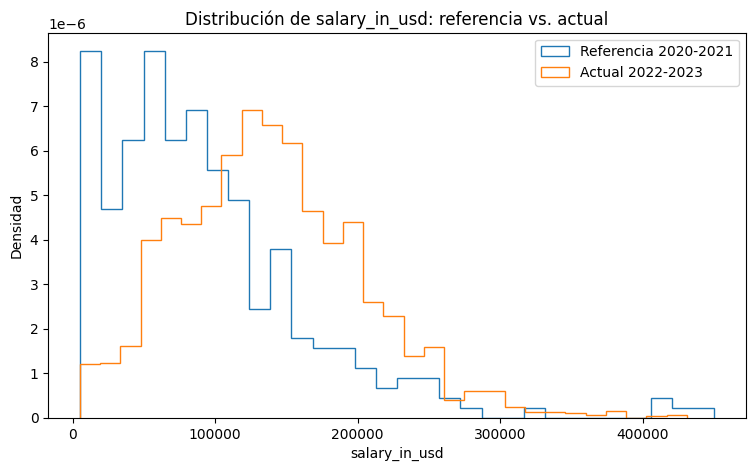

In [12]:
plt.figure(figsize=(9, 5))
plt.hist(
    reference_clean["salary_in_usd"],
    bins=30,
    density=True,
    histtype="step",
    label="Referencia 2020-2021"
)
plt.hist(
    actual_clean["salary_in_usd"],
    bins=30,
    density=True,
    histtype="step",
    label="Actual 2022-2023"
)
plt.xlabel("salary_in_usd")
plt.ylabel("Densidad")
plt.title("Distribución de salary_in_usd: referencia vs. actual")
plt.legend()
plt.show()

In [13]:
def distribution_table(col):
    out = pd.concat([
        reference_clean[col].value_counts(normalize=True).rename("Referencia"),
        actual_clean[col].value_counts(normalize=True).rename("Actual"),
    ], axis=1).fillna(0)

    out["Diferencia_pp"] = (out["Actual"] - out["Referencia"]) * 100
    return out

for col in ["experience_level", "remote_ratio", "company_size"]:
    print(f"Distribución de {col}")
    display(
        distribution_table(col).style.format({
            "Referencia": "{:.2%}",
            "Actual": "{:.2%}",
            "Diferencia_pp": "{:+.2f}"
        })
    )

Distribución de experience_level


,Referencia,Actual,Diferencia_pp
experience_level,,,
MI,40.26%,23.76%,-16.50
SE,30.03%,64.14%,+34.11
EN,25.41%,8.46%,-16.95
EX,4.29%,3.64%,-0.65


Distribución de remote_ratio


,Referencia,Actual,Diferencia_pp
remote_ratio,,,
100,51.82%,46.21%,-5.61
50,31.68%,3.99%,-27.69
0,16.50%,49.80%,+33.30


Distribución de company_size


,Referencia,Actual,Diferencia_pp
company_size,,,
L,52.48%,10.96%,-41.52
M,23.76%,85.75%,+61.99
S,23.76%,3.29%,-20.47


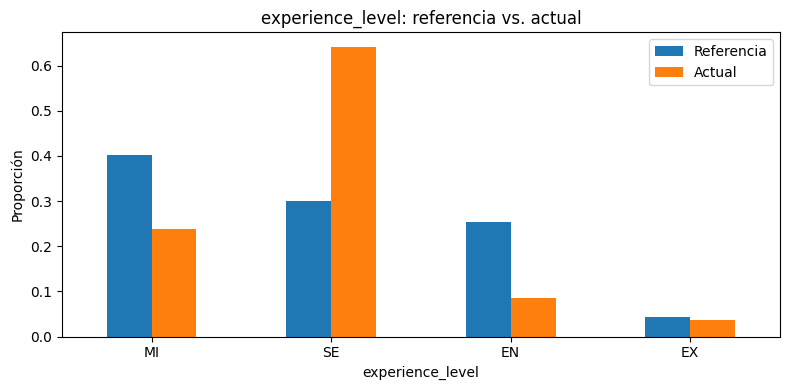

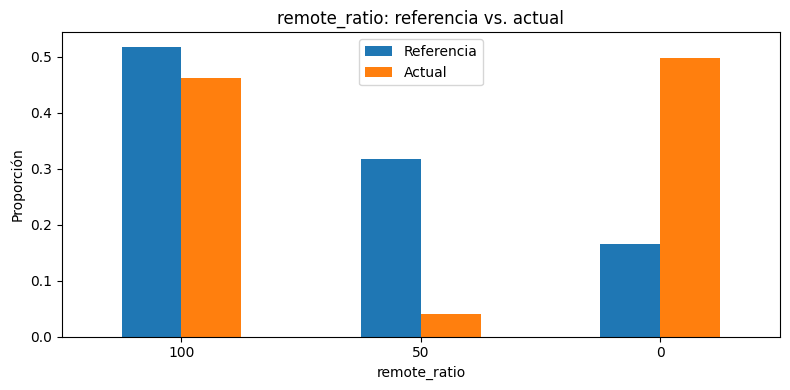

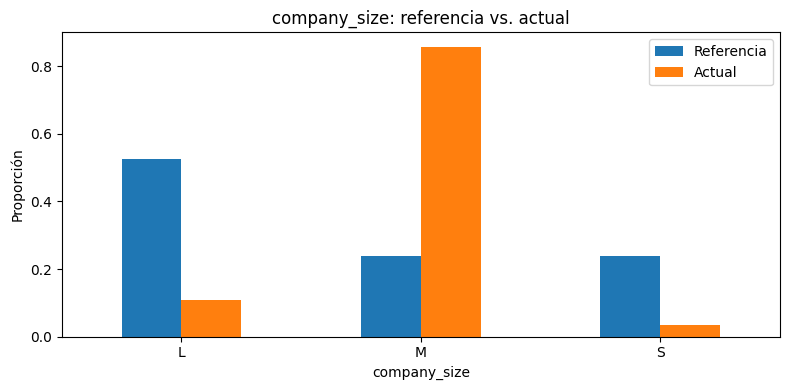

In [14]:
for col in ["experience_level", "remote_ratio", "company_size"]:
    dist = distribution_table(col)[["Referencia", "Actual"]]
    ax = dist.plot(kind="bar", figsize=(8, 4))
    ax.set_ylabel("Proporción")
    ax.set_title(f"{col}: referencia vs. actual")
    ax.set_xlabel(col)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

## 5.1 Interpretación del drift

Con un umbral de **PSI = 0.10**, las cuatro variables presentan drift incluso después de
eliminar duplicados.
En los datos limpios, las empresas
medianas (`M`) pasan de aproximadamente **23.76%** en referencia a **85.75%** en actual.
El trabajo presencial (`remote_ratio=0`) pasa de aproximadamente **16.50%** a **49.80%**,
mientras que el esquema 50% remoto baja de **31.68%** a **3.99%**. Además, los perfiles
senior (`SE`) pasan de cerca de **30.03%** a **64.14%**.

# 6. Estrategia para el modelo de la Actividad 1

La estrategia principal elegida es **reentrenamiento**.

Debido a lo siguiente:

1. Hay drift claro en varias variables de entrada y también en el target.
2. El modelo corregido de la Actividad 1 depende de información como `experience_level`,
   `job_title`, `employee_residence`, `remote_ratio` y `work_year`.
3. Un modelo entrenado mayormente con patrones de 2020–2021 puede quedar desactualizado ante
   una estructura laboral 2022–2023 diferente.
4. El reentrenamiento debe conservar la corrección metodológica de la Actividad 1:
   **eliminar duplicados y no usar `salary` ni `salary_currency` como predictores**.

Como evidencia adicional, a continuación se reproduce la arquitectura del modelo corregido
de la Actividad 1, pero entrenándolo solamente con 2020–2021 y evaluándolo temporalmente
sobre 2022–2023.

In [15]:
target = "salary_in_usd"
leakage_features = ["salary", "salary_currency"]

model_features = [
    c for c in df.columns
    if c not in [target] + leakage_features
]

X_ref = reference_clean[model_features]
y_ref = reference_clean[target]

X_actual = actual_clean[model_features]
y_actual = actual_clean[target]

categorical_features = X_ref.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_features = [
    c for c in model_features if c not in categorical_features
]

try:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", encoder, categorical_features),
        ("num", "passthrough", numeric_features)
    ]
)

temporal_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(random_state=RANDOM_STATE))
])

temporal_model.fit(X_ref, y_ref)

pred_ref = temporal_model.predict(X_ref)
pred_actual = temporal_model.predict(X_actual)

temporal_metrics = pd.DataFrame([{
    "R2_train_referencia": r2_score(y_ref, pred_ref),
    "R2_actual": r2_score(y_actual, pred_actual),
    "MAE_actual": mean_absolute_error(y_actual, pred_actual),
    "RMSE_actual": np.sqrt(mean_squared_error(y_actual, pred_actual))
}])

display(
    temporal_metrics.style.format({
        "R2_train_referencia": "{:.4f}",
        "R2_actual": "{:.4f}",
        "MAE_actual": "USD {:,.2f}",
        "RMSE_actual": "USD {:,.2f}"
    })
)

,R2_train_referencia,R2_actual,MAE_actual,RMSE_actual
0,0.9193,0.0967,"USD 45,927.65","USD 61,427.01"


### Conclusión sobre la estrategia

El test temporal del mismo pipeline corregido de la Actividad 1 arroja:

- **R² en referencia (train): 0.9193**
- **R² en actual 2022–2023: 0.0967**
- **MAE actual: USD 45,927.65**
- **RMSE actual: USD 61,427.01**

La caída de desempeño al trasladar el modelo desde 2020–2021 hacia 2022–2023 es consistente
con el drift detectado y refuerza la elección de **reentrenar con datos recientes**.

Una práctica razonable sería entrenar con una ventana móvil o con una mezcla ponderada que
dé mayor peso a observaciones recientes, validar siempre con un corte temporal y monitorear
PSI junto con métricas predictivas antes de desplegar una nueva versión.

# 7. Detección de anomalías: Isolation Forest y LOF

Parámetros:
- `contamination=0.05` en ambos métodos.
- `n_estimators=200` en Isolation Forest.
- `n_neighbors=20` en LOF.

In [16]:
anomaly_df = df_clean.copy()

experience_map = {"EN": 0, "MI": 1, "SE": 2, "EX": 3}
company_size_map = {"S": 0, "M": 1, "L": 2}

X_anomaly = pd.DataFrame({
    "salary_in_usd": anomaly_df["salary_in_usd"].astype(float),
    "remote_ratio": anomaly_df["remote_ratio"].astype(float),
    "experience_level_ord": anomaly_df["experience_level"].map(experience_map).astype(float),
    "company_size_ord": anomaly_df["company_size"].map(company_size_map).astype(float),
}, index=anomaly_df.index)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_anomaly)

display(X_anomaly.head())

,salary_in_usd,remote_ratio,experience_level_ord,company_size_ord
0,85847.0,100.0,2.0,2.0
1,30000.0,100.0,1.0,0.0
2,25500.0,100.0,1.0,0.0
3,175000.0,100.0,2.0,1.0
4,120000.0,100.0,2.0,1.0


## 7.1 Isolation Forest

In [17]:
if_model = IsolationForest(
    n_estimators=200,
    contamination=0.05,
    random_state=RANDOM_STATE
)

anomaly_df["if_pred"] = if_model.fit_predict(X_scaled)
anomaly_df["if_score"] = if_model.decision_function(X_scaled)

print(
    f"Anomalías detectadas por Isolation Forest: "
    f"{(anomaly_df['if_pred'] == -1).sum()} de {len(anomaly_df)}"
)

display(
    anomaly_df.sort_values("if_score").head(10)[
        [
            "work_year", "experience_level", "job_title",
            "salary_in_usd", "remote_ratio", "company_size",
            "if_pred", "if_score"
        ]
    ]
)

Anomalías detectadas por Isolation Forest: 130 de 2584


,work_year,experience_level,job_title,salary_in_usd,remote_ratio,company_size,if_pred,if_score
3675,2021,EX,Principal Data Scientist,416000,100,S,-1,-0.110223
3697,2020,EX,Director of Data Science,325000,100,L,-1,-0.079532
83,2022,EN,AI Developer,300000,50,L,-1,-0.068671
528,2023,SE,AI Scientist,423834,0,L,-1,-0.067244
3747,2021,MI,Applied Machine Learning Scientist,423000,50,L,-1,-0.064065
3593,2020,EN,Data Analyst,6072,0,S,-1,-0.063224
573,2023,EN,Autonomous Vehicle Technician,7000,0,S,-1,-0.063224
1548,2022,EN,AI Developer,6304,0,S,-1,-0.063224
2359,2022,SE,Data Science Tech Lead,375000,50,L,-1,-0.059833
478,2023,EX,Director of Data Science,353200,0,M,-1,-0.059226


## 7.2 Local Outlier Factor (LOF)

In [18]:
lof_model = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.05
)

anomaly_df["lof_pred"] = lof_model.fit_predict(X_scaled)
anomaly_df["lof_score"] = lof_model.negative_outlier_factor_

print(
    f"Anomalías detectadas por LOF: "
    f"{(anomaly_df['lof_pred'] == -1).sum()} de {len(anomaly_df)}"
)

display(
    anomaly_df.sort_values("lof_score").head(10)[
        [
            "work_year", "experience_level", "job_title",
            "salary_in_usd", "remote_ratio", "company_size",
            "lof_pred", "lof_score"
        ]
    ]
)

Anomalías detectadas por LOF: 130 de 2584


,work_year,experience_level,job_title,salary_in_usd,remote_ratio,company_size,lof_pred,lof_score
3609,2020,SE,Machine Learning Scientist,260000,0,S,-1,-22.458990
2651,2022,SE,Big Data Engineer,161311,50,M,-1,-21.694599
3613,2020,SE,Big Data Engineer,109024,50,M,-1,-21.333274
1339,2023,SE,Director of Data Science,125686,50,M,-1,-20.080784
3601,2021,SE,Big Data Architect,99703,50,M,-1,-15.317941
2254,2022,MI,BI Data Analyst,105066,50,M,-1,-9.971942
3505,2021,SE,Machine Learning Engineer,82744,50,M,-1,-9.711071
3628,2021,SE,Data Scientist,77684,50,M,-1,-9.337510
3275,2022,EX,Data Analyst,110000,100,M,-1,-9.106820
2711,2022,EX,Data Engineer,116100,100,M,-1,-8.210684


## 7.3 Comparación entre ambos métodos

In [19]:
both = (
    (anomaly_df["if_pred"] == -1)
    & (anomaly_df["lof_pred"] == -1)
)

only_if = (
    (anomaly_df["if_pred"] == -1)
    & (anomaly_df["lof_pred"] == 1)
)

only_lof = (
    (anomaly_df["if_pred"] == 1)
    & (anomaly_df["lof_pred"] == -1)
)

comparison_anomalies = pd.DataFrame([{
    "Isolation Forest (total)": int((anomaly_df["if_pred"] == -1).sum()),
    "LOF (total)": int((anomaly_df["lof_pred"] == -1).sum()),
    "Coinciden": int(both.sum()),
    "Solo Isolation Forest": int(only_if.sum()),
    "Solo LOF": int(only_lof.sum()),
}])

display(comparison_anomalies)

,Isolation Forest (total),LOF (total),Coinciden,Solo Isolation Forest,Solo LOF
0,130,130,36,94,94


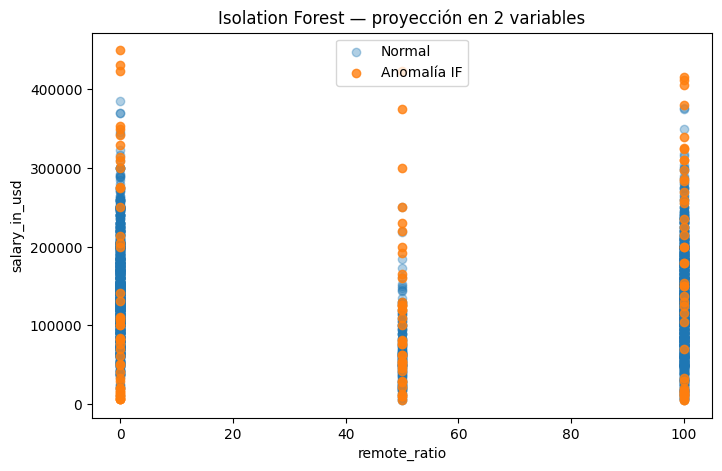

In [20]:
plt.figure(figsize=(8, 5))
normal_if = anomaly_df[anomaly_df["if_pred"] == 1]
anomaly_if = anomaly_df[anomaly_df["if_pred"] == -1]

plt.scatter(
    normal_if["remote_ratio"],
    normal_if["salary_in_usd"],
    alpha=0.35,
    label="Normal"
)
plt.scatter(
    anomaly_if["remote_ratio"],
    anomaly_if["salary_in_usd"],
    alpha=0.8,
    label="Anomalía IF"
)
plt.xlabel("remote_ratio")
plt.ylabel("salary_in_usd")
plt.title("Isolation Forest — proyección en 2 variables")
plt.legend()
plt.show()

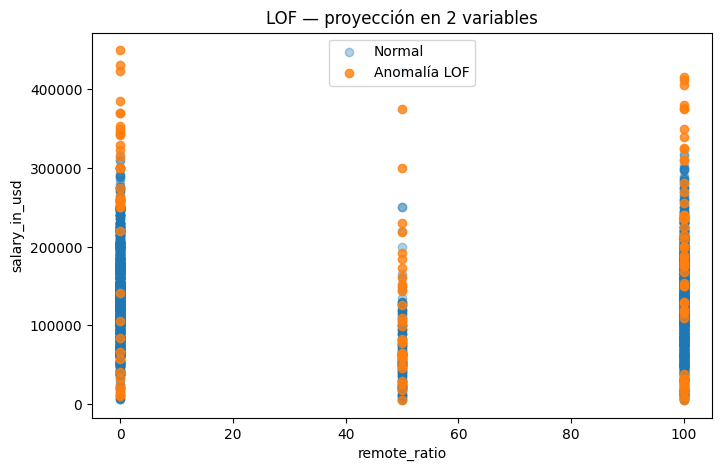

In [21]:
plt.figure(figsize=(8, 5))
normal_lof = anomaly_df[anomaly_df["lof_pred"] == 1]
anomaly_lof = anomaly_df[anomaly_df["lof_pred"] == -1]

plt.scatter(
    normal_lof["remote_ratio"],
    normal_lof["salary_in_usd"],
    alpha=0.35,
    label="Normal"
)
plt.scatter(
    anomaly_lof["remote_ratio"],
    anomaly_lof["salary_in_usd"],
    alpha=0.8,
    label="Anomalía LOF"
)
plt.xlabel("remote_ratio")
plt.ylabel("salary_in_usd")
plt.title("LOF — proyección en 2 variables")
plt.legend()
plt.show()

# 8. Análisis de un registro anómalo


In [22]:
if_only_candidates = anomaly_df[only_if].copy()

selected_idx = if_only_candidates["salary_in_usd"].idxmax()
selected = anomaly_df.loc[selected_idx]

selected_cols = [
    "work_year",
    "experience_level",
    "employment_type",
    "job_title",
    "salary_in_usd",
    "employee_residence",
    "remote_ratio",
    "company_location",
    "company_size",
    "if_pred",
    "if_score",
    "lof_pred",
    "lof_score",
]

print(f"Índice original seleccionado: {selected_idx}")
display(selected[selected_cols].to_frame("valor"))

Índice original seleccionado: 3747


,valor
work_year,2021
experience_level,MI
employment_type,FT
job_title,Applied Machine Learning Scientist
salary_in_usd,423000
employee_residence,US
remote_ratio,50
company_location,US
company_size,L
if_pred,-1


## 8.1 ¿Es un outlier univariado o multivariado?

In [23]:
salary_series = anomaly_df["salary_in_usd"]

q1 = salary_series.quantile(0.25)
q3 = salary_series.quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

salary_value = float(selected["salary_in_usd"])
percentile = 100 * (salary_series <= salary_value).mean()

univariate_salary_outlier = (
    salary_value < lower_fence or salary_value > upper_fence
)

univariate_summary = pd.DataFrame([{
    "salary_in_usd_registro": salary_value,
    "Q1": q1,
    "Q3": q3,
    "IQR": iqr,
    "limite_inferior": lower_fence,
    "limite_superior": upper_fence,
    "percentil_aprox": percentile,
    "outlier_univariado_por_IQR": "Sí" if univariate_salary_outlier else "No"
}])

display(
    univariate_summary.style.format({
        "salary_in_usd_registro": "USD {:,.2f}",
        "Q1": "USD {:,.2f}",
        "Q3": "USD {:,.2f}",
        "IQR": "USD {:,.2f}",
        "limite_inferior": "USD {:,.2f}",
        "limite_superior": "USD {:,.2f}",
        "percentil_aprox": "{:.2f}%"
    })
)

,salary_in_usd_registro,Q1,Q3,IQR,limite_inferior,limite_superior,percentil_aprox,outlier_univariado_por_IQR
0,"USD 423,000.00","USD 84,975.00","USD 175,000.00","USD 90,025.00","USD -50,062.50","USD 310,037.50",99.88%,Sí


In [24]:
category_context = pd.DataFrame([
    {
        "variable": col,
        "valor_registro": selected[col],
        "frecuencia_en_dataset_limpio": (
            anomaly_df[col].value_counts(normalize=True).loc[selected[col]]
        )
    }
    for col in ["experience_level", "remote_ratio", "company_size"]
])

display(
    category_context.style.format({
        "frecuencia_en_dataset_limpio": "{:.2%}"
    })
)

,variable,valor_registro,frecuencia_en_dataset_limpio
0,experience_level,MI,25.70%
1,remote_ratio,50,7.24%
2,company_size,L,15.83%


### Interpretación del registro seleccionado

El registro de índice original **3747** corresponde a un `Applied Machine Learning Scientist`
del año 2021, nivel `MI`, trabajo 50% remoto, empresa `L` y salario de **USD 423,000**.

En el dataset sin duplicados:

- Q1 de `salary_in_usd`: **USD 84,975**
- Q3: **USD 175,000**
- límite superior de 1.5·IQR: **USD 310,037.50**
- percentil aproximado del registro: **99.88%**

Como **USD 423,000 > USD 310,037.50**, el salario por sí solo ya cumple el criterio de outlier.
Por eso el registro se interpreta principalmente como un **outlier univariado en
`salary_in_usd`**.

Las otras variables son válidas: `MI` representa aproximadamente **25.70%** del dataset limpio,
`remote_ratio=50` aproximadamente **7.24%**, y `company_size=L` aproximadamente **15.83%**.

## 8.2 ¿Isolation Forest y LOF coinciden?

**No.** Para el registro seleccionado:

- Isolation Forest devuelve `-1` y un `if_score ≈ -0.0641`: lo marca como anomalía.
- LOF devuelve `1` y un `lof_score ≈ -1.5885`: no lo marca como anomalía.

La diferencia se explica por la lógica de cada método:

- **Isolation Forest** busca puntos que pueden aislarse rápidamente mediante particiones
  aleatorias. Un salario extremadamente alto puede separarse con pocas divisiones y, por ello,
  ser considerado raro a nivel global.
- **LOF** es un método **local**: compara la densidad del punto con la densidad de sus
  `k=20` vecinos. Un punto globalmente extremo puede no superar el umbral si su densidad local
  no es suficientemente menor que la de los vecinos que lo rodean.

En el conjunto completo sin duplicados, ambos métodos detectan **130 anomalías** cada uno,
pero solo coinciden en **36 registros**. Hay **94 casos exclusivos de Isolation Forest** y
**94 exclusivos de LOF**, lo que muestra que capturan nociones distintas de anomalía.